# Repair Technical Duration Regression — Experiment V1

**Mục tiêu:** dự đoán số phút kỹ thuật chủ động cần cho một công việc sửa chữa.

Mô hình ML chỉ trả về **technical duration**. ETA là bài toán vận hành khác:

$$
\text{ETA}=f(\widehat{\text{technical duration}},\;\text{queue},\;\text{schedule},\;\text{break},\;\text{current state})
$$

Notebook không gọi MySQL, không ghi `ml_predictions`, không tích hợp Spring Boot và không xây dựng mô hình phân loại sự hài lòng.

## 1. Phát biểu bài toán, sample và target

Sample V1 là phiếu đã hoàn tất với đúng một hạng mục được duyệt, một assignment kỹ thuật viên, không transfer và có status history liên tục. Giới hạn này tránh chia thời lượng ticket cho nhiều item hoặc gán toàn bộ thời lượng cho nhiều kỹ thuật viên mà schema không đo được.

Target production tương lai:

$$
y=\text{actual\_technical\_minutes}
=\left\lfloor\frac{\sum \operatorname{duration}\left((I_{inspect}\cup I_{repair})\cap I_{assignment}\right)}{60\text{ seconds}}\right\rfloor
$$

Không cộng `ASSIGNED`, `WAITING_APPROVAL`, `WAITING_PART`, break, transfer gap hay `WAITING_HANDOVER`. Production hiện chưa trừ `service_interruptions` khỏi duration; đây là giới hạn được ghi rõ trong data contract.

## 2. Dataset synthetic và giới hạn

CSV gồm 5.000 sample synthetic theo đúng feature contract có thể ánh xạ sang schema hiện tại. Target được sinh bởi hidden technician/specialty/branch/case factors, noise và một tỷ lệ nhỏ outlier. Các hidden factor không xuất hiện trong CSV.

Synthetic data chỉ kiểm tra pipeline và phương pháp nghiên cứu. Kết quả không chứng minh accuracy ngoài thực tế.

In [1]:
from pathlib import Path
import platform
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEED = 20261005
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")

ML_ROOT = Path.cwd()
if not (ML_ROOT / "data").exists() and (ML_ROOT / "ml" / "data").exists():
    ML_ROOT = ML_ROOT / "ml"
DATA_PATH = ML_ROOT / "data" / "synthetic_repair_duration_v1.csv"

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Seed:", SEED)
print("Dataset:", DATA_PATH.resolve())

Python: 3.13.6
pandas: 3.0.2
numpy: 2.4.4
scikit-learn: 1.8.0
joblib: 1.5.3
Seed: 20261005
Dataset: D:\Class\DOAN\CNPM\apple-repair-service\apple-repair-service\ml\data\synthetic_repair_duration_v1.csv


## 3. Đọc CSV và kiểm tra chất lượng ban đầu

In [2]:
df = pd.read_csv(
    DATA_PATH,
    parse_dates=["prediction_timestamp", "completed_at"],
)

print("Shape:", df.shape)
print("Duplicated rows:", int(df.duplicated().sum()))
print("Unique sample IDs:", df["sample_id"].nunique())
print("Chronological:", df["prediction_timestamp"].is_monotonic_increasing)
print("Date range:", df["prediction_timestamp"].min(), "->", df["completed_at"].max())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))

Shape: (5000, 18)
Duplicated rows: 0
Unique sample IDs: 5000
Chronological: True
Date range: 2025-01-02 08:05:00 -> 2026-09-29 22:16:00


,dtype,missing
sample_id,str,0
prediction_timestamp,datetime64[us],0
completed_at,datetime64[us],0
device_type,str,0
device_model,str,0
service_issue,str,0
service_type,str,0
catalog_service,str,0
standard_duration_minutes,int64,0
technician_id,str,0


In [3]:
display(df.head(5))
display(df.describe(include="all").transpose())

,sample_id,prediction_timestamp,completed_at,device_type,device_model,service_issue,service_type,catalog_service,standard_duration_minutes,technician_id,branch_id,prediction_month,prediction_weekday,technician_jobs_completed_before,technician_average_duration_before,technician_issue_experience_before,technician_historical_efficiency_before,actual_technical_minutes
0,SYN_RD_000001,2025-01-02 08:05:00,2025-01-02 09:54:00,iPhone,iPhone 14,Màn hình,REPLACEMENT,Thay màn hình iPhone 14,110,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,92
1,SYN_RD_000002,2025-01-02 08:25:00,2025-01-02 10:06:00,iPhone,iPhone 16 Pro,Pin,REPLACEMENT,Thay pin iPhone 16 Pro,75,TECH_01,BRANCH_02,M01,THU,0,NaN,0,NaN,81
2,SYN_RD_000003,2025-01-02 08:59:00,2025-01-02 10:36:00,iPhone,iPhone 16 Pro,Pin,WARRANTY,Xử lý bảo hành pin iPhone 16 Pro,70,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,78
3,SYN_RD_000004,2025-01-02 09:39:00,2025-01-02 11:06:00,iPhone,iPhone 16 Pro,Pin,WARRANTY,Xử lý bảo hành pin iPhone 16 Pro,70,TECH_01,BRANCH_01,M01,THU,0,NaN,0,NaN,67
4,SYN_RD_000005,2025-01-02 09:40:00,2025-01-02 12:35:00,iPhone,iPhone 14,Pin,REPLACEMENT,Thay pin iPhone 14,65,TECH_01,BRANCH_02,M01,THU,0,NaN,0,NaN,74


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
sample_id,5000,5000,SYN_RD_000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prediction_timestamp,5000,NaN,NaN,NaN,2025-11-17 10:53:38.616000,2025-01-02 08:05:00,2025-06-11 13:19:00,2025-11-19 13:26:00,2026-04-27 14:29:30,2026-09-29 17:36:00,NaN
completed_at,5000,NaN,NaN,NaN,2025-11-17 13:32:34.404000,2025-01-02 09:54:00,2025-06-11 16:00:00,2025-11-19 15:51:30,2026-04-27 16:30:15,2026-09-29 22:16:00,NaN
device_type,5000,3,iPhone,3231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_model,5000,9,iPhone 13,927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_issue,5000,6,Pin,2326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_type,5000,3,REPLACEMENT,3912,NaN,NaN,NaN,NaN,NaN,NaN,NaN
catalog_service,5000,24,Thay pin iPhone 13,380,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_duration_minutes,5000.0,NaN,NaN,NaN,114.201,60.0,75.0,110.0,130.0,260.0,48.546554
technician_id,5000,12,TECH_01,1042,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Chọn cột

**Numerical features:** thời lượng chuẩn và bốn historical aggregates as-of.

**Categorical features:** device, model, issue, type, catalog, technician, branch, month và weekday.

**Không dùng:** `sample_id` (identifier), timestamps (chỉ split/audit), `completed_at` (tương lai) và target. Feedback, future status, ETA error và hidden generator parameters không có trong dataset.

In [4]:
NUMERICAL_FEATURES = [
    "standard_duration_minutes",
    "technician_jobs_completed_before",
    "technician_average_duration_before",
    "technician_issue_experience_before",
    "technician_historical_efficiency_before",
]
CATEGORICAL_FEATURES = [
    "device_type",
    "device_model",
    "service_issue",
    "service_type",
    "catalog_service",
    "technician_id",
    "branch_id",
    "prediction_month",
    "prediction_weekday",
]
TARGET = "actual_technical_minutes"
NON_FEATURE_COLUMNS = ["sample_id", "prediction_timestamp", "completed_at"]
FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

assert len(df) == 5000
assert not df.duplicated().any()
assert df["sample_id"].is_unique
assert set(FEATURES + [TARGET] + NON_FEATURE_COLUMNS) == set(df.columns)
assert df[TARGET].notna().all()
print("Numerical:", NUMERICAL_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)
print("Target:", TARGET)
print("Non-feature:", NON_FEATURE_COLUMNS)

Numerical: ['standard_duration_minutes', 'technician_jobs_completed_before', 'technician_average_duration_before', 'technician_issue_experience_before', 'technician_historical_efficiency_before']
Categorical: ['device_type', 'device_model', 'service_issue', 'service_type', 'catalog_service', 'technician_id', 'branch_id', 'prediction_month', 'prediction_weekday']
Target: actual_technical_minutes
Non-feature: ['sample_id', 'prediction_timestamp', 'completed_at']


## 5. Temporal split

Các sample sớm nhất 85% tạo development set. 15% mới nhất được khóa làm test. Model và hyperparameter được chọn bằng `TimeSeriesSplit` chỉ trong development set; test không tham gia EDA, preprocessing fit hoặc model selection.

In [5]:
df = df.sort_values(["prediction_timestamp", "sample_id"]).reset_index(drop=True)
test_start = int(len(df) * 0.85)
development = df.iloc[:test_start].copy()
test = df.iloc[test_start:].copy()

X_dev, y_dev = development[FEATURES], development[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Development:", len(development), development.prediction_timestamp.min(), "->", development.prediction_timestamp.max())
print("Untouched test:", len(test), test.prediction_timestamp.min(), "->", test.prediction_timestamp.max())
assert development.prediction_timestamp.max() <= test.prediction_timestamp.min()

Development: 4250 2025-01-02 08:05:00 -> 2026-06-25 09:26:00
Untouched test: 750 2026-06-25 09:50:00 -> 2026-09-29 17:36:00


## 6. EDA chỉ trên development set

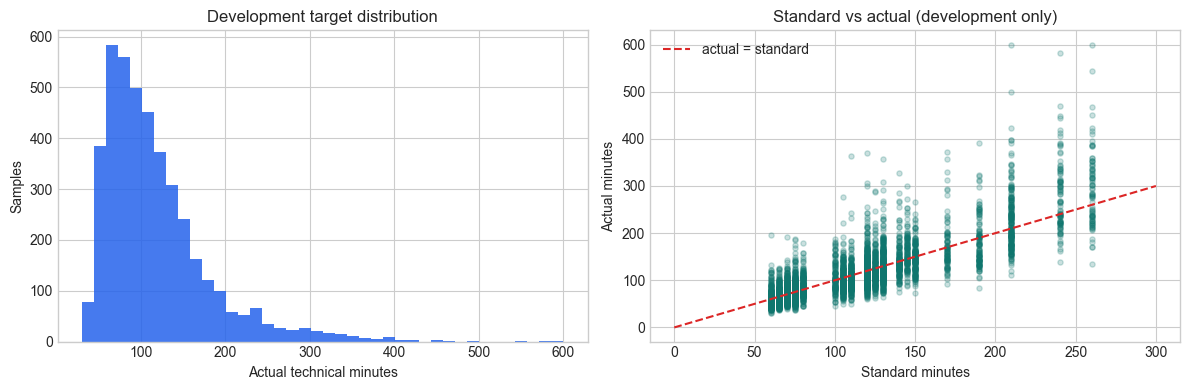

,actual_technical_minutes
count,4250.000000
mean,117.644000
std,64.613875
min,30.000000
25%,73.000000
50%,102.000000
75%,141.750000
max,600.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_dev, bins=40, color="#2563eb", alpha=0.85)
axes[0].set(title="Development target distribution", xlabel="Actual technical minutes", ylabel="Samples")
axes[1].scatter(development["standard_duration_minutes"], y_dev, alpha=0.22, s=14, color="#0f766e")
axes[1].plot([0, 300], [0, 300], "--", color="#dc2626", label="actual = standard")
axes[1].set(title="Standard vs actual (development only)", xlabel="Standard minutes", ylabel="Actual minutes")
axes[1].legend()
plt.tight_layout()
plt.show()

display(y_dev.describe().to_frame("actual_technical_minutes"))

In [7]:
development_eda = development.assign(
    actual_to_standard=development[TARGET] / development["standard_duration_minutes"]
)
display(
    development_eda.groupby("device_type").agg(
        samples=(TARGET, "size"),
        mean_actual=(TARGET, "mean"),
        mean_ratio=("actual_to_standard", "mean"),
    ).round(3)
)
display(
    development_eda.groupby("service_issue").agg(
        samples=(TARGET, "size"),
        mean_actual=(TARGET, "mean"),
        mean_ratio=("actual_to_standard", "mean"),
    ).sort_values("mean_actual", ascending=False).round(3)
)
display(
    development_eda[[
        "standard_duration_minutes",
        "technician_jobs_completed_before",
        "technician_average_duration_before",
        "technician_issue_experience_before",
        "technician_historical_efficiency_before",
        TARGET,
    ]].corr().round(3)
)

,samples,mean_actual,mean_ratio
device_type,,,
MacBook,801,187.232,1.043
iPad,684,135.020,1.046
iPhone,2765,93.186,1.026


,samples,mean_actual,mean_ratio
service_issue,,,
Mainboard,280,267.200,1.144
Bàn phím,195,179.097,0.990
Màn hình,1300,127.783,0.998
Cổng sạc,316,94.829,1.087
Pin,1999,90.815,1.034
Camera,160,78.900,1.052


,standard_duration_minutes,technician_jobs_completed_before,technician_average_duration_before,technician_issue_experience_before,technician_historical_efficiency_before,actual_technical_minutes
standard_duration_minutes,1.000,-0.001,-0.001,-0.228,-0.004,0.821
technician_jobs_completed_before,-0.001,1.000,-0.005,0.796,0.003,-0.027
technician_average_duration_before,-0.001,-0.005,1.000,-0.018,0.880,0.119
technician_issue_experience_before,-0.228,0.796,-0.018,1.000,-0.004,-0.217
technician_historical_efficiency_before,-0.004,0.003,0.880,-0.004,1.000,0.136
actual_technical_minutes,0.821,-0.027,0.119,-0.217,0.136,1.000


## 7. Preprocessing Pipeline

Categorical values use mode imputation and `OneHotEncoder(handle_unknown='ignore')`. Numeric values use median imputation learned inside each train fold. The linear model also standardizes numeric columns; tree models do not require scaling. No encoder, scaler or imputer is fit on the full dataset before splitting.

In [8]:
def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric = Pipeline(numeric_steps)
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, NUMERICAL_FEATURES),
        ("categorical", categorical, CATEGORICAL_FEATURES),
    ])


def regression_metrics(y_true, y_pred) -> dict:
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }


cv = TimeSeriesSplit(n_splits=4)


def temporal_cv_metrics(estimator) -> dict:
    observed, predicted = [], []
    for train_index, validation_index in cv.split(X_dev):
        fold_model = clone(estimator)
        fold_model.fit(X_dev.iloc[train_index], y_dev.iloc[train_index])
        observed.extend(y_dev.iloc[validation_index].tolist())
        predicted.extend(fold_model.predict(X_dev.iloc[validation_index]).tolist())
    return regression_metrics(np.asarray(observed), np.asarray(predicted))

## 8. Baselines

Mean baseline uses `DummyRegressor(strategy='mean')`. The business baseline is the currently configured catalog estimate:

$$\widehat{y}_{business}=\text{standard\_duration\_minutes}$$

ML must be compared with both; beating only the mean is not sufficient.

In [9]:
def baseline_cv_metrics() -> tuple[dict, dict]:
    observed, mean_predictions, standard_predictions = [], [], []
    for train_index, validation_index in cv.split(X_dev):
        fold_y_train = y_dev.iloc[train_index]
        fold_y_validation = y_dev.iloc[validation_index]
        dummy = DummyRegressor(strategy="mean")
        dummy.fit(np.zeros((len(fold_y_train), 1)), fold_y_train)
        observed.extend(fold_y_validation.tolist())
        mean_predictions.extend(dummy.predict(np.zeros((len(fold_y_validation), 1))).tolist())
        standard_predictions.extend(
            X_dev.iloc[validation_index]["standard_duration_minutes"].tolist()
        )
    observed = np.asarray(observed)
    return (
        regression_metrics(observed, np.asarray(mean_predictions)),
        regression_metrics(observed, np.asarray(standard_predictions)),
    )


mean_cv, standard_cv = baseline_cv_metrics()
display(pd.DataFrame([mean_cv, standard_cv], index=["Mean baseline", "Standard-duration baseline"]).round(3))

,MAE,MSE,RMSE,R2
Mean baseline,46.550,4162.605,64.518,-0.001
Standard-duration baseline,24.484,1387.490,37.249,0.666


## 9. Linear Regression

$$\widehat{y}=\beta_0+\sum_{j=1}^{p}\beta_jx_j$$

Ordinary Least Squares estimates coefficients by minimizing:

$$\min_{\beta}\sum_{i=1}^{n}(y_i-\widehat{y}_i)^2$$

In [10]:
linear_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=True)),
    ("model", LinearRegression()),
])
linear_cv = temporal_cv_metrics(linear_pipeline)
display(pd.DataFrame([linear_cv], index=["Linear Regression"]).round(3))

,MAE,MSE,RMSE,R2
Linear Regression,30.18,1785.596,42.256,0.57


## 10. Decision Tree Regressor

A regression tree selects splits that reduce squared error. For a candidate split into left/right nodes:

$$\Delta=\operatorname{MSE}(parent)-\left(\frac{n_L}{n}\operatorname{MSE}(L)+\frac{n_R}{n}\operatorname{MSE}(R)\right)$$

A small grid is tuned with temporal CV on development data only.

In [11]:
tree_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=False)),
    ("model", DecisionTreeRegressor(random_state=SEED)),
])
tree_search = GridSearchCV(
    tree_pipeline,
    param_grid={
        "model__max_depth": [5, 9, 13],
        "model__min_samples_leaf": [5, 15, 30],
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    refit=True,
)
tree_search.fit(X_dev, y_dev)
best_tree = tree_search.best_estimator_
tree_cv = temporal_cv_metrics(best_tree)
print("Best tree parameters:", tree_search.best_params_)
display(pd.DataFrame([tree_cv], index=["Decision Tree"]).round(3))

Best tree parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 30}


,MAE,MSE,RMSE,R2
Decision Tree,24.417,1332.046,36.497,0.68


## 11. Random Forest Regressor

Random Forest fits many decorrelated trees on bootstrap samples and averages their predictions:

$$\widehat{y}_{RF}(x)=\frac{1}{B}\sum_{b=1}^{B}T_b(x)$$

The averaging reduces variance relative to a single tree. Its small grid is also tuned only with temporal CV.

In [12]:
forest_pipeline = Pipeline([
    ("preprocess", make_preprocessor(scale_numeric=False)),
    ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
])
forest_search = GridSearchCV(
    forest_pipeline,
    param_grid={
        "model__n_estimators": [120],
        "model__max_depth": [None, 14],
        "model__min_samples_leaf": [2, 8],
        "model__max_features": [0.7, 1.0],
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1,
    refit=True,
)
forest_search.fit(X_dev, y_dev)
best_forest = forest_search.best_estimator_
forest_cv = temporal_cv_metrics(best_forest)
print("Best forest parameters:", forest_search.best_params_)
display(pd.DataFrame([forest_cv], index=["Random Forest"]).round(3))

Best forest parameters: {'model__max_depth': 14, 'model__max_features': 0.7, 'model__min_samples_leaf': 8, 'model__n_estimators': 120}


,MAE,MSE,RMSE,R2
Random Forest,23.466,1235.787,35.154,0.703


## 12. Chọn và khóa winner bằng CV — chưa đọc test target

In [13]:
cv_results = pd.DataFrame(
    [mean_cv, standard_cv, linear_cv, tree_cv, forest_cv],
    index=[
        "Mean baseline",
        "Standard-duration baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
    ],
).sort_values("MAE")
display(cv_results.round(3))

MODEL_CANDIDATES = {
    "Linear Regression": linear_pipeline,
    "Decision Tree": best_tree,
    "Random Forest": best_forest,
}
locked_winner_name = min(MODEL_CANDIDATES, key=lambda name: cv_results.loc[name, "MAE"])
locked_winner = clone(MODEL_CANDIDATES[locked_winner_name])
print("LOCKED WINNER (selected only by development temporal CV):", locked_winner_name)

,MAE,MSE,RMSE,R2
Random Forest,23.466,1235.787,35.154,0.703
Decision Tree,24.417,1332.046,36.497,0.680
Standard-duration baseline,24.484,1387.490,37.249,0.666
Linear Regression,30.180,1785.596,42.256,0.570
Mean baseline,46.550,4162.605,64.518,-0.001


LOCKED WINNER (selected only by development temporal CV): Random Forest


## 13. Đánh giá test đúng một lần sau khi khóa winner

Metrics:

$$\operatorname{MAE}=\frac{1}{n}\sum|y_i-\widehat{y}_i|$$

$$\operatorname{MSE}=\frac{1}{n}\sum(y_i-\widehat{y}_i)^2,\qquad
\operatorname{RMSE}=\sqrt{\operatorname{MSE}}$$

$$R^2=1-\frac{\sum(y_i-\widehat{y}_i)^2}{\sum(y_i-\bar{y})^2}$$

All candidate test metrics are reported transparently after the winner is locked; they do not change model selection.

In [14]:
test_predictions = {}

dummy = DummyRegressor(strategy="mean")
dummy.fit(np.zeros((len(y_dev), 1)), y_dev)
test_predictions["Mean baseline"] = dummy.predict(np.zeros((len(y_test), 1)))
test_predictions["Standard-duration baseline"] = X_test["standard_duration_minutes"].to_numpy()

fitted_models = {}
for name, candidate in MODEL_CANDIDATES.items():
    fitted = clone(candidate).fit(X_dev, y_dev)
    fitted_models[name] = fitted
    test_predictions[name] = fitted.predict(X_test)

test_results = pd.DataFrame(
    {name: regression_metrics(y_test, prediction) for name, prediction in test_predictions.items()}
).transpose().sort_values("MAE")
display(test_results.round(3))

winner_model = fitted_models[locked_winner_name]
winner_prediction = test_predictions[locked_winner_name]
print("Winner remains locked as:", locked_winner_name)
print("Winner beats standard-duration baseline on test MAE:", test_results.loc[locked_winner_name, "MAE"] < test_results.loc["Standard-duration baseline", "MAE"])

,MAE,MSE,RMSE,R2
Random Forest,24.755,1253.799,35.409,0.719
Linear Regression,25.208,1318.011,36.304,0.705
Decision Tree,25.398,1349.853,36.740,0.697
Standard-duration baseline,26.669,1539.301,39.234,0.655
Mean baseline,47.607,4483.242,66.957,-0.005


Winner remains locked as: Random Forest
Winner beats standard-duration baseline on test MAE: True


## 14. Residual và actual-vs-predicted analysis

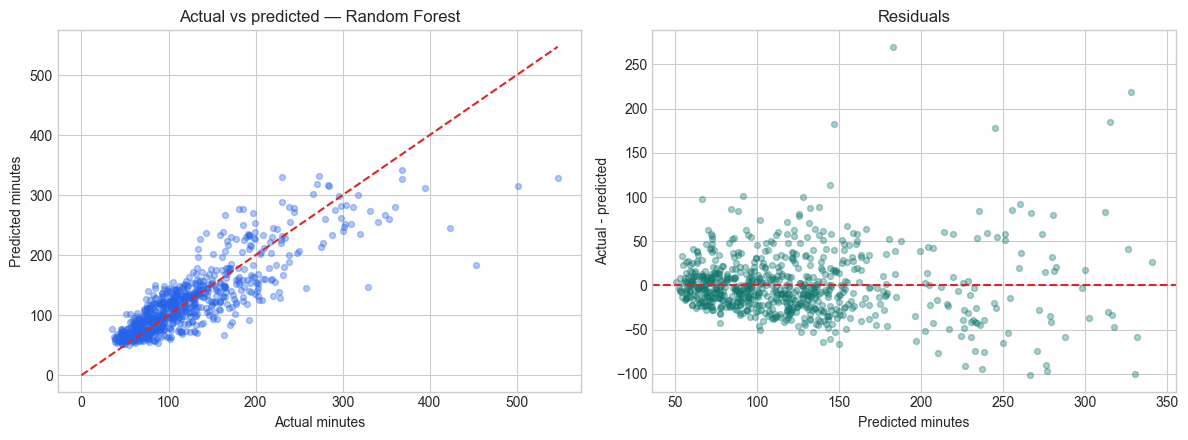

,residual
count,750.000000
mean,0.115164
std,35.432466
min,-101.422621
25%,-21.185666
50%,-4.621947
75%,14.137826
max,269.950811


In [15]:
residuals = y_test.to_numpy() - winner_prediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, winner_prediction, alpha=0.35, s=18, color="#2563eb")
limit = max(float(y_test.max()), float(np.max(winner_prediction)))
axes[0].plot([0, limit], [0, limit], "--", color="#dc2626")
axes[0].set(title=f"Actual vs predicted — {locked_winner_name}", xlabel="Actual minutes", ylabel="Predicted minutes")
axes[1].scatter(winner_prediction, residuals, alpha=0.35, s=18, color="#0f766e")
axes[1].axhline(0, linestyle="--", color="#dc2626")
axes[1].set(title="Residuals", xlabel="Predicted minutes", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()

display(pd.Series(residuals, name="residual").describe().to_frame())

In [16]:
error_analysis = test[["technician_id", "device_type", "service_issue"]].copy()
error_analysis["absolute_error"] = np.abs(residuals)

for group in ["technician_id", "device_type", "service_issue"]:
    summary = (
        error_analysis.groupby(group)
        .agg(samples=("absolute_error", "size"), MAE=("absolute_error", "mean"))
        .query("samples >= 10")
        .sort_values("MAE", ascending=False)
    )
    print(f"Error by {group}")
    display(summary.round(3))

Error by technician_id


,samples,MAE
technician_id,,
TECH_07,76,32.516
TECH_12,48,28.277
TECH_01,66,27.932
TECH_02,57,25.345
TECH_05,69,24.326
TECH_06,57,23.669
TECH_08,67,23.534
TECH_11,64,22.659
TECH_04,57,22.584


Error by device_type


,samples,MAE
device_type,,
MacBook,172,36.502
iPad,112,26.083
iPhone,466,20.100


Error by service_issue


,samples,MAE
service_issue,,
Mainboard,63,53.118
Bàn phím,39,32.042
Màn hình,233,25.605
Cổng sạc,64,20.631
Pin,327,19.301
Camera,24,15.513


## 15. Dự đoán sample mới và cold-start

`OneHotEncoder(handle_unknown='ignore')` accepts a technician unseen during training. Historical averages remain missing and are imputed by values learned only from development data. The prediction then relies on device/service/branch/time context and other observed features. This is a fallback, not evidence that a new technician has known performance.

In [17]:
new_samples = pd.DataFrame([
    {
        "standard_duration_minutes": 75,
        "technician_jobs_completed_before": 0,
        "technician_average_duration_before": np.nan,
        "technician_issue_experience_before": 0,
        "technician_historical_efficiency_before": np.nan,
        "device_type": "iPhone",
        "device_model": "iPhone 16 Pro",
        "service_issue": "Pin",
        "service_type": "REPLACEMENT",
        "catalog_service": "Thay pin iPhone 16 Pro",
        "technician_id": "TECH_NEW",
        "branch_id": "BRANCH_01",
        "prediction_month": "M10",
        "prediction_weekday": "MON",
    },
    {
        "standard_duration_minutes": 150,
        "technician_jobs_completed_before": 80,
        "technician_average_duration_before": 132.0,
        "technician_issue_experience_before": 14,
        "technician_historical_efficiency_before": 0.93,
        "device_type": "iPad",
        "device_model": "iPad 10",
        "service_issue": "Màn hình",
        "service_type": "REPLACEMENT",
        "catalog_service": "Thay màn hình iPad 10",
        "technician_id": "TECH_04",
        "branch_id": "BRANCH_02",
        "prediction_month": "M10",
        "prediction_weekday": "TUE",
    },
    {
        "standard_duration_minutes": 240,
        "technician_jobs_completed_before": 120,
        "technician_average_duration_before": 118.0,
        "technician_issue_experience_before": 18,
        "technician_historical_efficiency_before": 1.02,
        "device_type": "MacBook",
        "device_model": "MacBook Air M1",
        "service_issue": "Mainboard",
        "service_type": "REPAIR",
        "catalog_service": "Sửa mainboard MacBook Air M1",
        "technician_id": "TECH_07",
        "branch_id": "BRANCH_03",
        "prediction_month": "M10",
        "prediction_weekday": "WED",
    },
])[FEATURES]

sample_predictions = winner_model.predict(new_samples)
display(new_samples.assign(predicted_technical_minutes=np.round(sample_predictions, 1)))

,standard_duration_minutes,technician_jobs_completed_before,technician_average_duration_before,technician_issue_experience_before,technician_historical_efficiency_before,device_type,device_model,service_issue,service_type,catalog_service,technician_id,branch_id,prediction_month,prediction_weekday,predicted_technical_minutes
0,75,0,NaN,0,NaN,iPhone,iPhone 16 Pro,Pin,REPLACEMENT,Thay pin iPhone 16 Pro,TECH_NEW,BRANCH_01,M10,MON,73.5
1,150,80,132.0,14,0.93,iPad,iPad 10,Màn hình,REPLACEMENT,Thay màn hình iPad 10,TECH_04,BRANCH_02,M10,TUE,147.5
2,240,120,118.0,18,1.02,MacBook,MacBook Air M1,Mainboard,REPAIR,Sửa mainboard MacBook Air M1,TECH_07,BRANCH_03,M10,WED,293.8


## 16. Tổng kết thực nghiệm

In [18]:
winner_test = test_results.loc[locked_winner_name]
standard_test = test_results.loc["Standard-duration baseline"]
print(f"Selected model: {locked_winner_name}")
print(f"Test MAE: {winner_test.MAE:.3f} minutes")
print(f"Test RMSE: {winner_test.RMSE:.3f} minutes")
print(f"Test R2: {winner_test.R2:.3f}")
print(f"Standard baseline test MAE: {standard_test.MAE:.3f} minutes")
print("Selection used development TimeSeriesSplit only; test was evaluated after locking.")

Selected model: Random Forest
Test MAE: 24.755 minutes
Test RMSE: 35.409 minutes
Test R2: 0.719
Standard baseline test MAE: 26.669 minutes
Selection used development TimeSeriesSplit only; test was evaluated after locking.


### Kết luận và giới hạn

- Winner được chọn bằng temporal CV trên development set, không bằng test.
- Preprocessing nằm trong `Pipeline`; imputer/encoder/scaler không fit trước split.
- Business standard-duration baseline luôn được báo cáo riêng.
- Dataset synthetic chứng minh pipeline có thể chạy end-to-end, không chứng minh accuracy production.
- V1 chỉ áp dụng sample một item, một technician, không transfer và history đầy đủ.
- Production duration hiện chưa tự trừ `service_interruptions`; cần một label-contract version mới nếu logic đó được triển khai.
- Trước integration phải xây extractor as-of từ dữ liệu thật, đánh giá drift/cold-start và kiểm định trên holdout thực tế.
- Không lưu model artifact trong phase này vì chưa có dữ liệu thực để phê duyệt triển khai.